# 01 · The target

SPEC 03, roadmap Stage 0 and 2.2. Train races only. `race_pace_delta_pct` is the driver's median clean lap
over the field's median clean lap, minus one, in %. Rows are drivers inside races, so they are **not
independent**: every interval below that matters resamples whole races, never single rows, with the seed
of `config/training.json`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve().parents[1]
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "notebooks" / "exploratory")]

from provisional import DATASET_PATH  # noqa: E402

from common.config import load_config  # noqa: E402

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update(
    {"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False}
)
SEED = load_config().optuna.seed
rng = np.random.default_rng(SEED)
df = pd.read_parquet(DATASET_PATH)
valid = df[df["is_valid_row"]].copy()
n_races = valid[["year", "round"]].drop_duplicates().shape[0]
print(f"{len(df)} rows, {len(valid)} valid, {n_races} train races, seed {SEED}")
from scipy import stats  # noqa: E402
from scipy.signal import find_peaks  # noqa: E402

1118 rows, 1050 valid, 56 train races, seed 42


## 1. Units, range and shape

In [2]:
y = valid["race_pace_delta_pct"]
summary = pd.Series(
    {
        "n": len(y),
        "mean": y.mean(),
        "median": y.median(),
        "std": y.std(),
        "MAD (normal scale)": stats.median_abs_deviation(y, scale="normal"),
        "min": y.min(),
        "max": y.max(),
        "skew": stats.skew(y),
        "excess kurtosis": stats.kurtosis(y),
    }
)
print(summary.round(3).to_string())
qs = [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]
print()
print(y.quantile(qs).round(3).rename("quantile").to_string())
per_race_median = valid.groupby(["year", "round"])["race_pace_delta_pct"].median()
print(
    "\nmedian of the per-race medians:",
    round(per_race_median.median(), 3),
    "| range of per-race medians:",
    per_race_median.min().round(3),
    "to",
    per_race_median.max().round(3),
)

n                     1050.000
mean                     0.031
median                   0.057
std                      1.007
MAD (normal scale)       0.892
min                     -2.743
max                     16.799
skew                     4.374
excess kurtosis         71.881

0.001   -2.588
0.010   -1.921
0.050   -1.361
0.250   -0.622
0.500    0.057
0.750    0.600
0.950    1.398
0.990    1.897
0.999    3.293

median of the per-race medians: 0.065 | range of per-race medians: -0.338 to 0.632


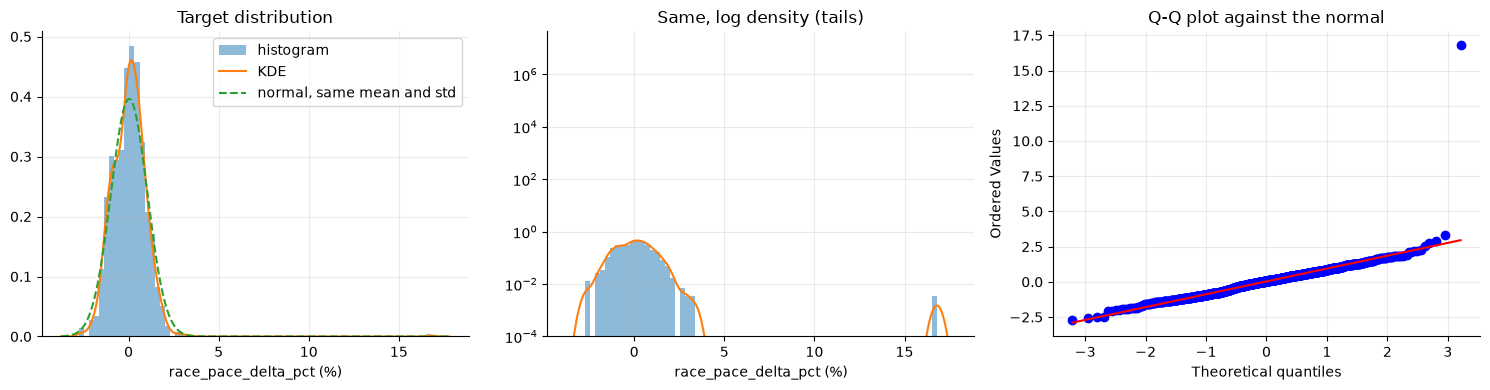

In [3]:
grid = np.linspace(y.min() - 1, y.max() + 1, 600)
kde = stats.gaussian_kde(y)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(y, bins=70, density=True, alpha=0.5, label="histogram")
ax[0].plot(grid, kde(grid), label="KDE")
ax[0].plot(grid, stats.norm.pdf(grid, y.mean(), y.std()), "--", label="normal, same mean and std")
ax[0].set(title="Target distribution", xlabel="race_pace_delta_pct (%)")
ax[0].legend()
ax[1].hist(y, bins=70, density=True, alpha=0.5)
ax[1].plot(grid, kde(grid))
ax[1].set(yscale="log", ylim=(1e-4, None), title="Same, log density (tails)", xlabel="race_pace_delta_pct (%)")
stats.probplot(y, dist="norm", plot=ax[2])
ax[2].set_title("Q-Q plot against the normal")
plt.tight_layout()
plt.show()

## 2. Bounds, clipping, zero inflation and modes

Clipping or censoring would show as many rows piled on one value at a bound; zero inflation as a spike at 0.

In [4]:
print("lowest:", y.nsmallest(5).round(3).tolist())
print("highest:", y.nlargest(5).round(3).tolist())
print("rows equal to the min:", int((y == y.min()).sum()), "| to the max:", int((y == y.max()).sum()))
print("most repeated values (rounded to 3 decimals):")
print(y.round(3).value_counts().head(4).to_string())
spike = (y.abs() < 0.02).mean()
expected = kde(0.0)[0] * 0.04
print(f"\nshare of rows within +-0.02: {spike:.3f} (a smooth density would give about {expected:.3f})")
density = kde(grid)
peaks, props = find_peaks(density, prominence=0.02 * density.max())
print(
    "KDE peaks (%):",
    grid[peaks].round(2).tolist(),
    "| prominence share of the top peak:",
    (props["prominences"] / density.max()).round(2).tolist(),
)

lowest: [-2.743, -2.591, -2.513, -2.465, -2.09]
highest: [16.799, 3.312, 2.918, 2.775, 2.57]
rows equal to the min: 1 | to the max: 1
most repeated values (rounded to 3 decimals):
race_pace_delta_pct
-0.018    4
 0.379    4
 0.500    3
 0.361    3

share of rows within +-0.02: 0.023 (a smooth density would give about 0.018)
KDE peaks (%): [0.14] | prominence share of the top peak: [1.0]


## 3. Spread by year, team and circuit type

In [5]:
def spread(frame, by):
    g = frame.groupby(by)["race_pace_delta_pct"]
    out = pd.DataFrame(
        {
            "n": g.size(),
            "mean": g.mean(),
            "median": g.median(),
            "std": g.std(),
            "MAD": g.apply(lambda s: stats.median_abs_deviation(s, scale="normal")),
            "IQR": g.quantile(0.75) - g.quantile(0.25),
            "p95_abs": g.apply(lambda s: s.abs().quantile(0.95)),
        }
    )
    return out.round(3)


for by in ("year", "circuit_type", "team"):
    print(spread(valid, by).sort_values("median").to_string(), "\n")

        n   mean  median    std    MAD    IQR  p95_abs
year                                                  
2023  413  0.046   0.002  1.127  0.777  1.041    1.528
2024  451  0.020   0.078  0.909  1.028  1.459    1.585
2025  186  0.025   0.127  0.957  0.867  1.230    1.897 

                n   mean  median    std    MAD    IQR  p95_abs
circuit_type                                                  
permanent     659  0.024   0.029  1.035  0.857  1.174    1.467
street        225  0.057   0.090  1.010  1.052  1.398    1.846
hybrid        166  0.024   0.102  0.889  0.873  1.212    1.814 

                   n   mean  median    std    MAD    IQR  p95_abs
team                                                             
Red Bull Racing  104 -0.792  -0.934  0.771  0.596  0.810    1.835
McLaren          109 -0.724  -0.781  0.784  0.764  0.990    1.925
Ferrari          109 -0.616  -0.763  0.718  0.520  0.679    1.466
Mercedes         110 -0.500  -0.573  0.601  0.497  0.653    1.347
Aston Mart

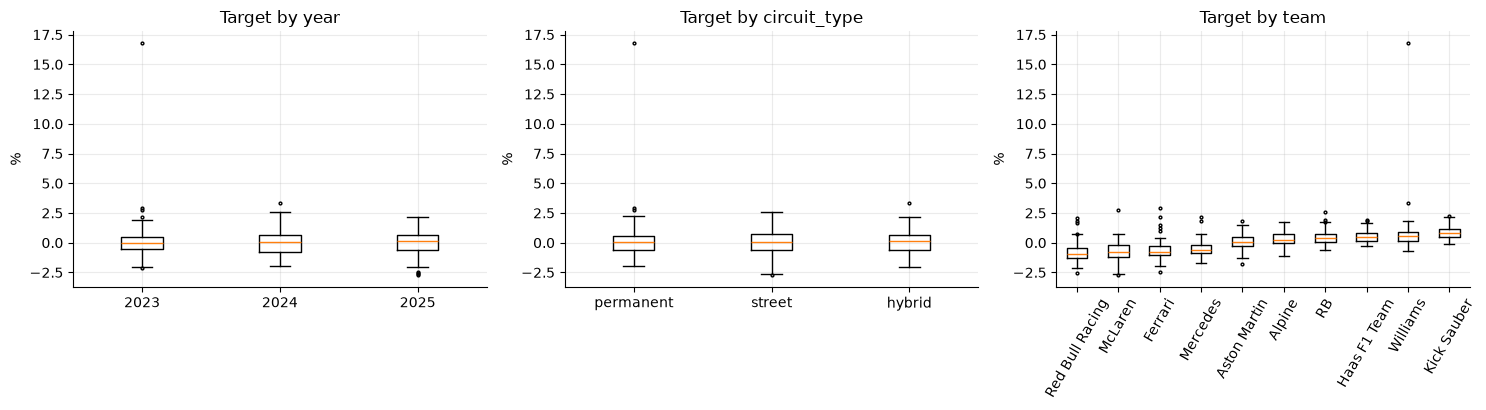

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, by in zip(ax, ("year", "circuit_type", "team"), strict=True):
    order = valid.groupby(by)["race_pace_delta_pct"].median().sort_values().index
    a.boxplot(
        [valid.loc[valid[by] == k, "race_pace_delta_pct"] for k in order],
        tick_labels=order,
        showfliers=True,
        flierprops={"markersize": 2},
    )
    a.set(title=f"Target by {by}", ylabel="%")
    a.tick_params(axis="x", rotation=60 if by == "team" else 0)
plt.tight_layout()
plt.show()

In [7]:
def race_bootstrap(stat, frame=None, draws=1000):
    """95% interval of `stat(frame)` resampling whole races, never single rows."""
    frame = valid if frame is None else frame
    key = frame["year"].astype(str) + "-" + frame["round"].astype(str)
    groups = [g.index.to_numpy() for _, g in frame.groupby(key)]
    values = []
    for _ in range(draws):
        pick = rng.integers(0, len(groups), len(groups))
        values.append(stat(frame.loc[np.concatenate([groups[i] for i in pick])]))
    return np.percentile(values, [2.5, 97.5]).round(3)


def std_of(frame):
    return frame["race_pace_delta_pct"].std()


print("std of the target, all train:", round(y.std(), 3), race_bootstrap(std_of))
for year in (2023, 2024, 2025):
    sub = valid[valid["year"] == year]
    print(f"std in {year} ({sub[['round']].nunique().iloc[0]} races): {std_of(sub):.3f}", race_bootstrap(std_of, sub))

std of the target, all train: 1.007 [0.813 1.268]
std in 2023 (22 races): 1.127 [0.708 1.638]


std in 2024 (24 races): 0.909 [0.83  0.993]
std in 2025 (10 races): 0.957 [0.72  1.196]


## 4. Heteroscedasticity

Does the spread of the target change with its level, or with the qualifying gap? The reference fit is the
qualifying baseline (OLS on `quali_delta_pct`), used here only to look at residuals.

In [8]:
base = valid.dropna(subset=["quali_delta_pct"]).copy()
slope, intercept = np.polyfit(base["quali_delta_pct"], base["race_pace_delta_pct"], 1)
base["fitted"] = intercept + slope * base["quali_delta_pct"]
base["resid"] = base["race_pace_delta_pct"] - base["fitted"]
print(f"baseline fit: target = {intercept:.3f} + {slope:.3f} * quali_delta_pct  (n={len(base)})")
base["bin"] = pd.qcut(base["quali_delta_pct"], 8, duplicates="drop")
table = (
    base.groupby("bin", observed=True)
    .agg(
        n=("resid", "size"),
        quali_mid=("quali_delta_pct", "median"),
        target_median=("race_pace_delta_pct", "median"),
        target_std=("race_pace_delta_pct", "std"),
        resid_std=("resid", "std"),
        resid_mae=("resid", lambda r: r.abs().mean()),
    )
    .round(3)
)
print(table.to_string())
rho = stats.spearmanr(base["quali_delta_pct"], base["resid"].abs())
print(
    "\nSpearman(|residual|, quali_delta_pct):",
    round(rho.statistic, 3),
    race_bootstrap(lambda f: stats.spearmanr(f["quali_delta_pct"], f["resid"].abs()).statistic, base, 500),
)
team_level = valid.groupby("team")["race_pace_delta_pct"].agg(["mean", "std"])
print(
    "Spearman(team mean, team std) over",
    len(team_level),
    "teams:",
    round(stats.spearmanr(team_level["mean"], team_level["std"]).statistic, 3),
)

baseline fit: target = -0.177 + 0.124 * quali_delta_pct  (n=1050)
                   n  quali_mid  target_median  target_std  resid_std  resid_mae
bin                                                                             
(-0.001, 0.297]  132      0.049         -1.023       0.516      0.515      0.881
(0.297, 0.601]   131      0.431         -0.758       0.574      0.573      0.677
(0.601, 0.893]   131      0.754         -0.245       0.583      0.582      0.475
(0.893, 1.209]   131      1.066          0.076       0.675      0.674      0.478
(1.209, 1.58]    131      1.379          0.243       0.645      0.644      0.518
(1.58, 1.981]    131      1.775          0.509       0.635      0.636      0.621
(1.981, 2.568]   131      2.242          0.663       0.605      0.603      0.695
(2.568, 45.596]  132      3.493          0.682       1.566      1.709      0.927



Spearman(|residual|, quali_delta_pct): -0.018 [-0.096  0.06 ]
Spearman(team mean, team std) over 10 teams: -0.479


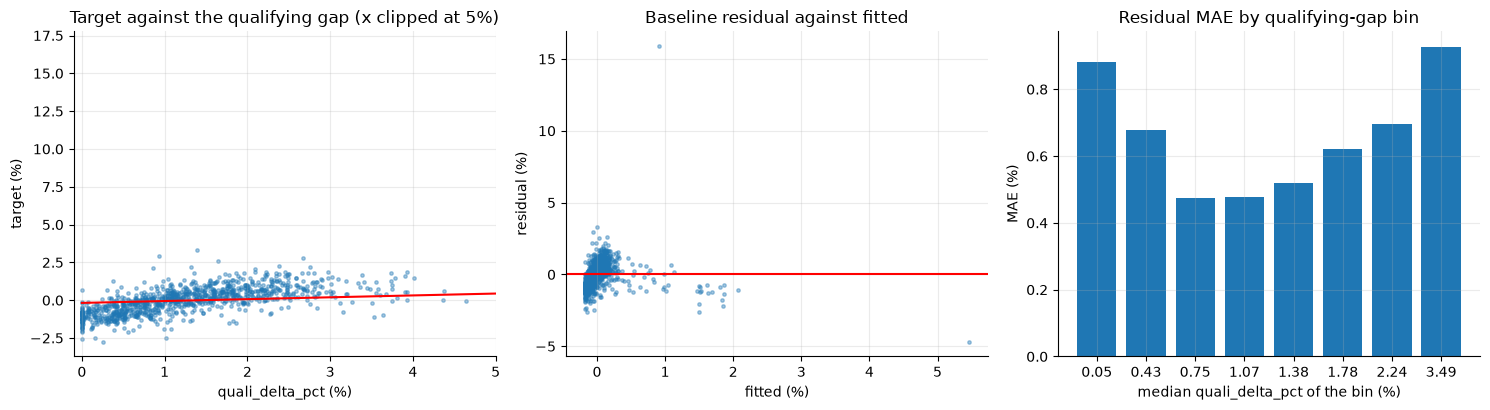

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].scatter(base["quali_delta_pct"], base["race_pace_delta_pct"], s=6, alpha=0.4)
xs = np.linspace(0, 5, 50)
ax[0].plot(xs, intercept + slope * xs, "r")
ax[0].set(
    xlim=(-0.1, 5),
    title="Target against the qualifying gap (x clipped at 5%)",
    xlabel="quali_delta_pct (%)",
    ylabel="target (%)",
)
ax[1].scatter(base["fitted"], base["resid"], s=6, alpha=0.4)
ax[1].axhline(0, color="r")
ax[1].set(title="Baseline residual against fitted", xlabel="fitted (%)", ylabel="residual (%)")
ax[2].bar(range(len(table)), table["resid_mae"], tick_label=table["quali_mid"].round(2))
ax[2].set(title="Residual MAE by qualifying-gap bin", xlabel="median quali_delta_pct of the bin (%)", ylabel="MAE (%)")
plt.tight_layout()
plt.show()

## 5. The target over the races: trend, seasonality and autocorrelation

The series is the spread of the target inside each race (the target is relative to the field, so its level
is fixed by construction), plus the persistence of a driver's own target from one race to the next.

In [10]:
races = (
    valid.groupby(["year", "round"])
    .agg(
        std=("race_pace_delta_pct", "std"),
        mad=("race_pace_delta_pct", lambda s: stats.median_abs_deviation(s, scale="normal")),
        top=("race_pace_delta_pct", "max"),
        circuit_type=("circuit_type", "first"),
        rain=("rain_flag", "max"),
    )
    .reset_index()
)
races["order"] = np.arange(len(races))
print(
    "races:",
    len(races),
    "| spread (std) of the target inside a race: median",
    races["std"].median().round(3),
    "min",
    races["std"].min().round(3),
    "max",
    races["std"].max().round(3),
)
print(
    "trend, Spearman(race order, std):",
    round(stats.spearmanr(races["order"], races["std"]).statistic, 3),
    "p =",
    round(stats.spearmanr(races["order"], races["std"]).pvalue, 3),
)
print(races.groupby("year")["std"].median().round(3).to_dict(), "(median race spread by year)")
print(races.groupby("circuit_type")["std"].agg(["size", "median"]).round(3).to_string())
print(races.groupby("rain")["std"].agg(["size", "median"]).round(3).to_string(), "(rain in qualifying)")
third = pd.cut(races["round"], [0, 8, 16, 30], labels=["early", "mid", "late"])
print(races.groupby(third, observed=True)["std"].agg(["size", "median"]).round(3).to_string(), "(season position)")


def acf(series, lags=10):
    x = np.asarray(series, dtype=float) - np.mean(series)
    return np.array([np.sum(x[k:] * x[: len(x) - k]) / np.sum(x * x) for k in range(1, lags + 1)])


race_acf = acf(races["std"])
band = 1.96 / np.sqrt(len(races))
print("\nACF of the race spread, lags 1-10:", race_acf.round(2).tolist(), "| 95% band +-", round(band, 2))

races: 56 | spread (std) of the target inside a race: median 0.845 min 0.483 max 3.903
trend, Spearman(race order, std): 0.167 p = 0.22
{2023: 0.784, 2024: 0.921, 2025: 0.845} (median race spread by year)
              size  median
circuit_type              
hybrid           9   0.692
permanent       35   0.828
street          12   0.957
      size  median
rain              
0       43   0.845
1       13   0.692 (rain in qualifying)
       size  median
round              
early    24   0.805
mid      18   0.918
late     14   0.817 (season position)

ACF of the race spread, lags 1-10: [-0.09, -0.09, -0.1, 0.01, -0.07, -0.07, 0.06, -0.1, -0.09, -0.03] | 95% band +- 0.26


driver lag-1: Pearson 0.453, Spearman 0.634, n pairs 1022 [0.337 0.618]
team lag-1: Pearson 0.568, n pairs 547


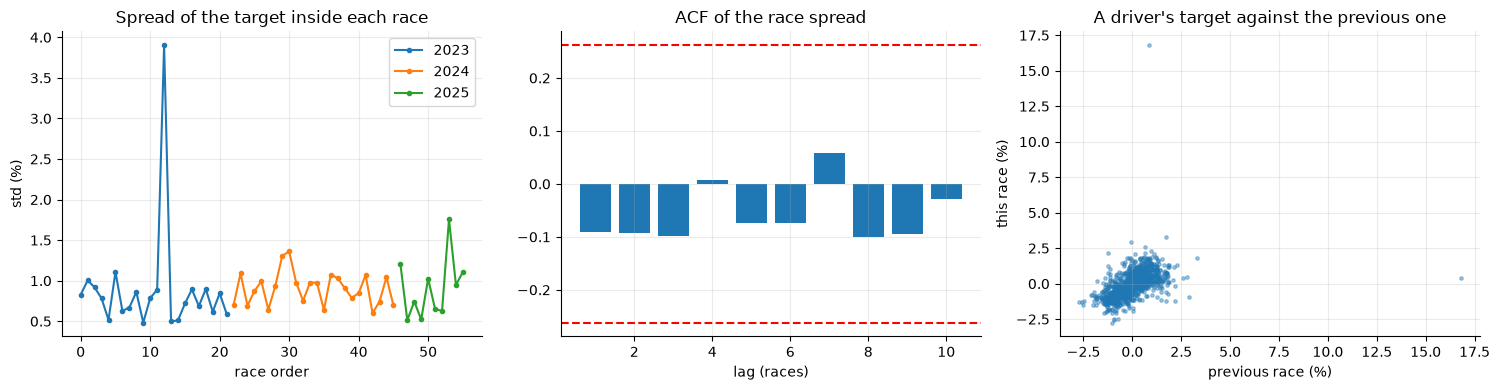

In [11]:
ordered = valid.sort_values(["year", "round"])
ordered["previous"] = ordered.groupby("driver")["race_pace_delta_pct"].shift(1)
pairs = ordered.dropna(subset=["previous"])
rho_driver = stats.spearmanr(pairs["previous"], pairs["race_pace_delta_pct"]).statistic
pearson = pairs["previous"].corr(pairs["race_pace_delta_pct"])
print(
    f"driver lag-1: Pearson {pearson:.3f}, Spearman {rho_driver:.3f}, n pairs {len(pairs)}",
    race_bootstrap(lambda f: f["previous"].corr(f["race_pace_delta_pct"]), pairs, 500),
)
team_races = (
    valid.groupby(["team", "year", "round"])["race_pace_delta_pct"].mean().reset_index().sort_values(["year", "round"])
)
team_races["previous"] = team_races.groupby("team")["race_pace_delta_pct"].shift(1)
t = team_races.dropna(subset=["previous"])
print(f"team lag-1: Pearson {t['previous'].corr(t['race_pace_delta_pct']):.3f}, n pairs {len(t)}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for year, color in zip((2023, 2024, 2025), ("C0", "C1", "C2"), strict=True):
    r = races[races["year"] == year]
    ax[0].plot(r["order"], r["std"], "o-", ms=3, color=color, label=str(year))
ax[0].set(title="Spread of the target inside each race", xlabel="race order", ylabel="std (%)")
ax[0].legend()
ax[1].bar(range(1, 11), race_acf)
ax[1].axhline(band, color="r", ls="--")
ax[1].axhline(-band, color="r", ls="--")
ax[1].set(title="ACF of the race spread", xlabel="lag (races)")
ax[2].scatter(pairs["previous"], pairs["race_pace_delta_pct"], s=6, alpha=0.4)
ax[2].set(title="A driver's target against the previous one", xlabel="previous race (%)", ylabel="this race (%)")
plt.tight_layout()
plt.show()

## 6. Noise floor

Two hands-on reads of the error no model can remove, as the roadmap asks. Twins that differ only by noise give
`y_i - y_j = e_i - e_j`, so under roughly normal noise the best achievable MAE is about `mean|y_i - y_j| / sqrt(2)`.
Both reads are rough: teammates are different drivers, and with continuous features true twins are rare, so
treat the numbers as a check on label quality, not as a bound.

In [12]:
mates = valid.dropna(subset=["teammate_quali_gap"])
pairs_t = mates.merge(mates, on=["year", "round", "team"], suffixes=("", "_b"))
pairs_t = pairs_t[pairs_t["driver"] < pairs_t["driver_b"]]
pairs_t["dy"] = (pairs_t["race_pace_delta_pct"] - pairs_t["race_pace_delta_pct_b"]).abs()
rows = []
for limit in (0.1, 0.2, 0.3, 0.5, np.inf):
    sel = pairs_t[pairs_t["teammate_quali_gap"].abs() < limit]
    rows.append(
        {
            "|teammate_quali_gap| <": limit,
            "pairs": len(sel),
            "mean |dy|": sel["dy"].mean(),
            "noise MAE ~ mean|dy|/sqrt2": sel["dy"].mean() / np.sqrt(2),
        }
    )
print(pd.DataFrame(rows).round(3).to_string(index=False))

 |teammate_quali_gap| <  pairs  mean |dy|  noise MAE ~ mean|dy|/sqrt2
                    0.1     60      0.325                       0.230
                    0.2    121      0.349                       0.247
                    0.3    177      0.371                       0.262
                    0.5    263      0.394                       0.278
                    inf    493      0.534                       0.378


In [13]:
from sklearn.neighbors import NearestNeighbors

cols = ["quali_delta_pct", "grid_position", "driver_pace_last3", "team_pace_last3"]
pool = valid.dropna(subset=cols).copy()
pool["grid_position"] = pool["grid_position"].astype(float)
z = (pool[cols] - pool[cols].mean()) / pool[cols].std()
dist, idx = NearestNeighbors(n_neighbors=40).fit(z).kneighbors(z)
race_of = (pool["year"] * 100 + pool["round"]).to_numpy()
target = pool["race_pace_delta_pct"].to_numpy()
best = []
for i in range(len(pool)):
    for d, j in zip(dist[i], idx[i], strict=True):
        if race_of[j] != race_of[i]:
            best.append((d, abs(target[i] - target[j])))
            break
best = pd.DataFrame(best, columns=["distance", "dy"])
near = best[best["distance"] <= best["distance"].quantile(0.25)]
print(f"{len(pool)} rows with the four features; nearest twin from another race")
print(f"all: mean |dy| {best['dy'].mean():.3f} -> noise MAE ~ {best['dy'].mean() / np.sqrt(2):.3f}")
reach, close = near["distance"].max(), near["dy"].mean()
print(f"closest quarter (distance <= {reach:.2f}): mean |dy| {close:.3f} -> noise MAE ~ {close / np.sqrt(2):.3f}")

1020 rows with the four features; nearest twin from another race
all: mean |dy| 0.570 -> noise MAE ~ 0.403
closest quarter (distance <= 0.13): mean |dy| 0.487 -> noise MAE ~ 0.344


## 7. Metric and loss

In [14]:
e_median = y - y.median()
e_mean = y - y.mean()
mae_median, mae_mean = e_median.abs().mean(), e_mean.abs().mean()
rmse = np.sqrt((e_mean**2).mean())
sq = np.sort((e_mean**2).to_numpy())[::-1]
print(f"constant at the median: MAE {mae_median:.3f} | at the mean: MAE {mae_mean:.3f} | RMSE (mean) {rmse:.3f}")
print(f"RMSE / MAE = {rmse / mae_mean:.2f} (1.25 for a normal target; higher means heavier tails)")
worst1, worst5 = sq[: len(sq) // 100].sum() / sq.sum(), sq[: len(sq) // 20].sum() / sq.sum()
print(f"share of the squared error from the worst 1% of rows: {worst1:.2f}, worst 5%: {worst5:.2f}")
print(f"share of positive residuals around the median: {(e_median > 0).mean():.2f} (0.50 if symmetric)")
print("median-dummy MAE by year:", {k: round((g - g.median()).abs().mean(), 3) for k, g in y.groupby(valid["year"])})
print(
    "median-dummy MAE 95% interval over races:",
    race_bootstrap(lambda f: (f["race_pace_delta_pct"] - f["race_pace_delta_pct"].median()).abs().mean()),
)

constant at the median: MAE 0.705 | at the mean: MAE 0.705 | RMSE (mean) 1.007
RMSE / MAE = 1.43 (1.25 for a normal target; higher means heavier tails)
share of the squared error from the worst 1% of rows: 0.33, worst 5%: 0.46
share of positive residuals around the median: 0.50 (0.50 if symmetric)
median-dummy MAE by year: {2023: np.float64(0.64), 2024: np.float64(0.747), 2025: np.float64(0.739)}


median-dummy MAE 95% interval over races: [0.641 0.768]


One row sits far from all the others (the highest target is 16.8% and the next is 3.3%). How much of the
shape and of the loss comparison is that single row?

In [15]:
rest = y[y < y.max()]
e = rest - rest.mean()
ratio = np.sqrt((e**2).mean()) / e.abs().mean()
print(
    f"without the top row (n={len(rest)}): skew {stats.skew(rest):.3f}, excess kurtosis {stats.kurtosis(rest):.3f}, "
    f"std {rest.std():.3f}, RMSE/MAE {ratio:.2f}"
)
row = valid.loc[
    y.idxmax(), ["year", "round", "circuit", "driver", "team", "clean_laps", "quali_delta_pct", "rain_flag"]
]
print(row.to_string())

without the top row (n=1049): skew 0.016, excess kurtosis -0.008, std 0.864, RMSE/MAE 1.25
year                    2023
round                     13
circuit            Zandvoort
driver                   SAR
team                Williams
clean_laps                13
quali_delta_pct     8.759052
rain_flag                  1


## 8. Does the target need a transform?

In [16]:
yj, lam = stats.yeojohnson(y)
clipped = y.clip(y.quantile(0.01), y.quantile(0.99))
table = pd.DataFrame(
    {
        "raw": [stats.skew(y), stats.kurtosis(y), y.std()],
        "Yeo-Johnson": [stats.skew(yj), stats.kurtosis(yj), np.std(yj, ddof=1)],
        "clipped at 1%/99%": [stats.skew(clipped), stats.kurtosis(clipped), clipped.std()],
    },
    index=["skew", "excess kurtosis", "std"],
).round(3)
print(table.to_string(), f"\n(Yeo-Johnson lambda {lam:.3f})")
top = valid.nlargest(8, "race_pace_delta_pct")[
    ["year", "round", "circuit", "driver", "team", "race_pace_delta_pct", "clean_laps", "rain_flag"]
]
print("\nhighest targets:")
print(top.round(3).to_string(index=False))

                    raw  Yeo-Johnson  clipped at 1%/99%
skew              4.374        0.278             -0.036
excess kurtosis  71.881        6.931             -0.498
std               1.007        0.924              0.844 
(Yeo-Johnson lambda 0.655)

highest targets:
 year  round           circuit driver        team  race_pace_delta_pct  clean_laps  rain_flag
 2023     13         Zandvoort    SAR    Williams               16.799          13          1
 2024      9          Montreal    SAR    Williams                3.312          22          1
 2023     12 Spa-Francorchamps    SAI     Ferrari                2.918          20          1
 2023      1            Sakhir    PIA     McLaren                2.775          12          0
 2024     17              Baku    TSU          RB                2.570          11          0
 2024     12       Silverstone    ZHO Kick Sauber                2.277          41          1
 2025      8       Monte Carlo    ANT    Mercedes                2.192  

## Figures for the summary

In [17]:
FIGURES = ROOT / "docs" / "eda" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.savefig(FIGURES / name, dpi=100, bbox_inches="tight")
    plt.close(fig)
    print("saved", (FIGURES / name).relative_to(ROOT))


fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(y, bins=70, density=True, alpha=0.5, label="histogram")
ax[0].plot(grid, kde(grid), label="KDE")
ax[0].plot(grid, stats.norm.pdf(grid, y.mean(), y.std()), "--", label="normal, same mean and std")
ax[0].set(
    title=f"Target distribution ({len(y):,} training rows)",
    xlabel="race_pace_delta_pct (%)",
    ylabel="density",
    xlim=(-4, 4),
)
ax[0].text(0.03, 0.55, "one row at 16.8% is off the\nscale (see the Q-Q plot)", transform=ax[0].transAxes, fontsize=7)
ax[0].legend(fontsize=8, loc="upper left")
stats.probplot(y, dist="norm", plot=ax[1])
ax[1].set_title("Q-Q plot against the normal")
save(fig, "01_target_distribution.png")

order = valid.groupby("team")["race_pace_delta_pct"].median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.boxplot(
    [valid.loc[valid["team"] == t, "race_pace_delta_pct"] for t in order],
    tick_labels=order,
    orientation="horizontal",
    flierprops={"markersize": 2},
)
ax.axvline(0, color="grey", lw=0.8)
ax.set(title="Target by team (training rows)", xlabel="race_pace_delta_pct (%)", xlim=(-3.5, 4))
ax.text(0.02, 0.97, "Williams: one row at 16.8%\nis off the scale", transform=ax.transAxes, fontsize=7, va="top")
save(fig, "02_target_by_team.png")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(pairs["previous"], pairs["race_pace_delta_pct"], s=6, alpha=0.4)
ax[0].set(
    title=f"A driver's target against the previous race\n(Spearman {rho_driver:.2f}, {len(pairs):,} pairs)",
    xlabel="previous race (%)",
    ylabel="this race (%)",
    xlim=(-3.5, 3.5),
    ylim=(-3.5, 3.5),
)
ax[0].text(
    0.03,
    0.03,
    "axes cut at +-3.5: the two pairs that\ninclude the 16.8% row are outside",
    transform=ax[0].transAxes,
    fontsize=7,
)
for year, color in zip((2023, 2024, 2025), ("C0", "C1", "C2"), strict=True):
    r = races[races["year"] == year]
    ax[1].plot(r["order"], r["std"], "o-", ms=3, color=color, label=str(year))
ax[1].set(title="Spread of the target inside each race", xlabel="race order", ylabel="std (%)", ylim=(0.4, 2.0))
ax[1].text(
    0.03,
    0.95,
    f"Zandvoort 2023 (race order 12) is off the scale: std {races['std'].max():.1f}",
    transform=ax[1].transAxes,
    fontsize=7,
    va="top",
)
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
save(fig, "03_target_persistence.png")

saved docs/eda/figures/01_target_distribution.png
saved docs/eda/figures/02_target_by_team.png


saved docs/eda/figures/03_target_persistence.png


## Findings

Suggested decisions (they reach `DECISIONS.md` in step 13, after the review of the summary):

1. **No target transform.** The raw skew (4.37) and excess kurtosis (71.9) come from one row. Without it they are 0.02 and -0.01 and the RMSE/MAE ratio is 1.25, the value of a normal target. Yeo-Johnson or a log would only chase that row.
2. **One extreme row to settle in `02`.** 2023 round 13, Zandvoort, SAR (Williams): target 16.8%, 13 clean laps, rain, an 8.8% qualifying gap. The next highest target is 3.3%. It alone takes the training MAE and squared-error fits away from the rest; whether it is a genuine wet-race lap or an error, and whether the answer is a stricter valid-row threshold or a cap on the training target, is decided with the outlier analysis.
3. **MAE stays the main metric.** Residuals around the median are symmetric (50% positive), so there is no case for a quantile loss. The median and mean dummies score the same MAE (0.705, 95% interval over races 0.64–0.77). For Phase 4: the models default to squared error, which the extreme row distorts (the worst 1% of rows carry 33% of the squared error); an L1 or Huber objective would be an Optuna choice, and `ALLOWED_PARAMS` has no `objective` yet.
4. **Realistic error floor: about 0.25–0.40.** Teammates with an equal qualifying time (gap under 0.1–0.3%) and nearest twins from other races give a noise MAE of 0.23–0.40, against 0.705 for the median dummy. A model below roughly 0.3 would be suspicious.

What the data says, with no decision attached:

- **No clipping, no zero inflation, one mode.** The minimum and maximum are single rows, the density has one peak (0.14%) and the share within ±0.02 is 2.3% against 1.8% expected. The range is -2.7% to +3.3% apart from the extreme row.
- **Team is the main structure.** Team medians go from -0.93 (Red Bull) to +0.82 (Kick Sauber), with a spread of 0.47–0.77 inside a team (Williams 1.75 only because of the extreme row). Years and circuit types barely differ (std 0.91–1.13 and 0.89–1.04, with overlapping intervals over races).
- **No heteroscedasticity in the monotone sense.** Spearman between |baseline residual| and `quali_delta_pct` is -0.02 [-0.10, 0.06]. What the bins show is a non-linear, saturating relation: the target median goes from -1.02 (best qualifiers) to +0.68 and is flat beyond a 2% gap, so a straight line fits the middle badly (residual MAE 0.88 in the best bin). The last bin (gap above 2.6%, up to 45.6%) has the largest spread and decides the slope of the linear baseline; this is the case for the 3% cap, checked in `02`.
- **No trend, seasonality or autocorrelation in the race spread** (Spearman with race order 0.17, p = 0.22; ACF within ±0.26 at every lag). Chronological order matters for the split, not as a feature.
- **Form persists.** A driver's target against their previous race: Spearman 0.63, Pearson 0.45 [0.34, 0.62] (1,022 pairs); for a team 0.57. This supports `driver_pace_last3` and `team_pace_last3`, to be measured in `03`.